In [23]:
from pathlib import Path
import pandas as pd
import sys

def find_project_dir(start: Path = Path.cwd()) -> Path:
    for folder in (start.resolve(), *start.resolve().parents):
        if (folder / "data" / "raw" / "train.csv").is_file():
            return folder

    raise FileNotFoundError(
        f"Could not find the project (looked for data/raw/train.csv) from {start.resolve()}"
    )

PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / "data" / "raw"

## print("Python:", sys.executable)
## print("Thư mục dữ liệu:", DATA_DIR)
## ^ chuyển 2 dòng này thành comment để tránh print ra thông tin cá nhân, khi check có thể bỏ comment để debug
print("Thư mục tồn tại:", DATA_DIR.exists())
print("Các file:", [p.name for p in DATA_DIR.glob("*.csv")])

train = pd.read_csv(DATA_DIR / "train.csv")
stores = pd.read_csv(DATA_DIR / "stores.csv")
weather = pd.read_csv(DATA_DIR / "weather.csv")
holidays = pd.read_csv(DATA_DIR / "holidays.csv")

print("Train:", train.shape)
print("Stores:", stores.shape)
print("Weather:", weather.shape)
print("Holidays:", holidays.shape)

display(train.head())

Thư mục tồn tại: True
Các file: ['holidays.csv', 'sample_submission.csv', 'stores.csv', 'train.csv', 'weather.csv']
Train: (26632, 4)
Stores: (45, 8)
Weather: (1593, 4)
Holidays: (55, 3)


,date,store_id,is_promo,revenue
0,2024-01-01,S02,0,6.44
1,2024-01-01,S03,0,8.86
2,2024-01-01,S04,0,17.08
3,2024-01-01,S05,0,29.15
4,2024-01-01,S06,0,8.16


In [17]:
from pathlib import Path

def find_project_dir(start: Path = Path.cwd()) -> Path:
    for folder in (start.resolve(), *start.resolve().parents):
        if (folder / "data" / "raw" / "train.csv").is_file():
            return folder

    raise FileNotFoundError(
        f"Could not find the project (looked for data/raw/train.csv) from {start.resolve()}"
    )

PROJECT_DIR = find_project_dir()

print("Các file Python trong project:")
for f in PROJECT_DIR.rglob("*.py"):
    print(f.relative_to(PROJECT_DIR))

Các file Python trong project:
notebooks\load.py
notebooks\validate.py
src\data_cleaning_rules.py


In [18]:
# ===== EDA 2: KIỂM TRA CHẤT LƯỢNG DỮ LIỆU =====
import pandas as pd
import numpy as np

datasets = {
    "train": train,
    "stores": stores,
    "weather": weather,
    "holidays": holidays
}

# 1. Kiểm tra dữ liệu thiếu
for name, df in datasets.items():
    print(f"\n===== {name.upper()} =====")
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "unique_values": df.nunique()
    }))

# 2. Kiểm tra dữ liệu trùng
print("\n===== KIỂM TRA TRÙNG LẶP =====")
print("Train trùng date + store_id:",
      train.duplicated(["date", "store_id"]).sum())
print("Stores trùng store_id:",
      stores["store_id"].duplicated().sum())
print("Weather trùng date + city:",
      weather.duplicated(["date", "city"]).sum())
print("Holidays trùng date + holiday_name:",
      holidays.duplicated(["date", "holiday_name"]).sum())

# 3. Chuẩn hóa open_date
def parse_mixed_dates(values):
    s = values.astype("string").str.strip()

    result = pd.Series(
        pd.NaT,
        index=values.index,
        dtype="datetime64[ns]"
    )

    iso = s.str.match(
        r"^\d{4}-\d{1,2}-\d{1,2}$",
        na=False
    )

    result.loc[iso] = pd.to_datetime(
        s.loc[iso],
        format="%Y-%m-%d",
        errors="coerce"
    )

    result.loc[~iso] = pd.to_datetime(
        s.loc[~iso],
        format="%d/%m/%Y",
        errors="coerce"
    )

    return result

stores_clean = stores.copy()
stores_clean["open_date_raw"] = stores_clean["open_date"]
stores_clean["open_date"] = parse_mixed_dates(
    stores_clean["open_date_raw"]
)

print("\n===== OPEN_DATE SAU CHUẨN HÓA =====")
print("Ngày không chuyển đổi được:",
      stores_clean["open_date"].isna().sum())
display(stores_clean[
    ["store_id", "open_date_raw", "open_date"]
].head(15))

# 4. Chuẩn hóa ngày của các bảng
train_clean = train.copy()
train_clean["date"] = pd.to_datetime(
    train_clean["date"], errors="coerce"
)

weather_clean = weather.copy()
weather_clean["date"] = pd.to_datetime(
    weather_clean["date"], errors="coerce"
)

holidays_clean = holidays.copy()
holidays_clean["date"] = pd.to_datetime(
    holidays_clean["date"], errors="coerce"
)

print("\n===== PHẠM VI NGÀY =====")
print("Train:", train_clean["date"].min(),
      "->", train_clean["date"].max())
print("Weather:", weather_clean["date"].min(),
      "->", weather_clean["date"].max())
print("Holidays:", holidays_clean["date"].min(),
      "->", holidays_clean["date"].max())

print("\n===== KIỂM TRA GIÁ TRỊ =====")
print("is_promo không thuộc 0/1:",
      (~train_clean["is_promo"].isin([0, 1])).sum())
print("temp_c thiếu:", weather_clean["temp_c"].isna().sum())
print("rain_mm thiếu:", weather_clean["rain_mm"].isna().sum())
print("area_m2 thiếu:", stores_clean["area_m2"].isna().sum())
print("area_m2 <= 0:",
      (stores_clean["area_m2"] <= 0).sum())


===== TRAIN =====


,dtype,missing_count,missing_pct,unique_values
date,str,0,0.0,731
store_id,str,0,0.0,45
is_promo,int64,0,0.0,2
revenue,float64,0,0.0,3995



===== STORES =====


,dtype,missing_count,missing_pct,unique_values
store_id,str,0,0.00,45
city,str,0,0.00,2
district,str,0,0.00,19
store_type,str,0,0.00,9
area_m2,float64,2,4.44,36
seats,int64,0,0.00,31
has_parking,int64,0,0.00,2
open_date,str,0,0.00,44



===== WEATHER =====


...


===== HOLIDAYS =====


,dtype,missing_count,missing_pct,unique_values
date,str,0,0.0,53
holiday_name,str,0,0.0,15
type,str,0,0.0,2



===== KIỂM TRA TRÙNG LẶP =====
Train trùng date + store_id: 132
Stores trùng store_id: 0
Weather trùng date + city: 0
Holidays trùng date + holiday_name: 0

===== OPEN_DATE SAU CHUẨN HÓA =====
Ngày không chuyển đổi được: 0


,store_id,open_date_raw,open_date
0,S01,2025-12-07,2025-12-07
1,S02,27/07/2022,2022-07-27
2,S03,12/03/2018,2018-03-12
3,S04,17/04/2019,2019-04-17
4,S05,2020-12-24,2020-12-24
5,S06,2019-11-16,2019-11-16
6,S07,2025-06-10,2025-06-10
7,S08,2025-05-09,2025-05-09
8,S09,2025-02-10,2025-02-10
9,S10,2022-06-27,2022-06-27



===== PHẠM VI NGÀY =====
Train: 2024-01-01 00:00:00 -> 2025-12-31 00:00:00
Weather: 2024-01-01 00:00:00 -> 2026-03-31 00:00:00
Holidays: 2024-01-01 00:00:00 -> 2026-03-08 00:00:00

===== KIỂM TRA GIÁ TRỊ =====
is_promo không thuộc 0/1: 0
temp_c thiếu: 0
rain_mm thiếu: 16
area_m2 thiếu: 2
area_m2 <= 0: 0


In [19]:
# Xem các bản ghi trùng theo ngày và cửa hàng
duplicate_rows = train_clean[
    train_clean.duplicated(
        subset=["date", "store_id"],
        keep=False
    )
].sort_values(["date", "store_id"])

print("Số dòng thuộc nhóm trùng:",
      len(duplicate_rows))

display(duplicate_rows.head(30))

# Kiểm tra trùng hoàn toàn trên tất cả các cột
print(
    "Số dòng trùng hoàn toàn:",
    train_clean.duplicated().sum()
)

# Kiểm tra các nhóm trùng có doanh thu khác nhau không
duplicate_summary = (
    duplicate_rows
    .groupby(["date", "store_id"])
    .agg(
        so_ban_ghi=("revenue", "size"),
        so_muc_doanh_thu=("revenue", "nunique"),
        so_muc_promo=("is_promo", "nunique"),
        doanh_thu_min=("revenue", "min"),
        doanh_thu_max=("revenue", "max")
    )
    .reset_index()
)

display(duplicate_summary.head(30))

Số dòng thuộc nhóm trùng: 264


,date,store_id,is_promo,revenue
368,2024-01-11,S39,0,15.80
369,2024-01-11,S39,0,15.80
406,2024-01-13,S04,0,17.93
407,2024-01-13,S04,0,17.93
832,2024-01-25,S34,0,17.92
833,2024-01-25,S34,0,17.92
863,2024-01-26,S30,0,16.93
864,2024-01-26,S30,0,16.93
964,2024-01-29,S29,0,26.63
965,2024-01-29,S29,0,26.63


Số dòng trùng hoàn toàn: 132


,date,store_id,so_ban_ghi,so_muc_doanh_thu,so_muc_promo,doanh_thu_min,doanh_thu_max
0,2024-01-11,S39,2,1,1,15.80,15.80
1,2024-01-13,S04,2,1,1,17.93,17.93
2,2024-01-25,S34,2,1,1,17.92,17.92
3,2024-01-26,S30,2,1,1,16.93,16.93
4,2024-01-29,S29,2,1,1,26.63,26.63
5,2024-02-06,S40,2,1,1,23.27,23.27
6,2024-02-27,S40,2,1,1,20.75,20.75
7,2024-03-16,S33,2,1,1,13.30,13.30
8,2024-03-17,S40,2,1,1,32.44,32.44
9,2024-03-19,S21,2,1,1,18.69,18.69


In [20]:
# Tạo bản sao để xử lý
stores_model = stores_clean.copy()
weather_model = weather_clean.copy()

# Điền area_m2 bằng trung vị của store_type
stores_model["area_m2"] = (
    stores_model["area_m2"]
    .fillna(
        stores_model.groupby("store_type")["area_m2"]
        .transform("median")
    )
)

# Nếu một nhóm store_type không có trung vị,
# dùng trung vị chung làm phương án dự phòng
stores_model["area_m2"] = (
    stores_model["area_m2"]
    .fillna(stores_model["area_m2"].median())
)

# Chưa tự động coi rain_mm thiếu là không mưa.
# Điền bằng 0 chỉ khi dữ liệu xác nhận giá trị thiếu có nghĩa là không mưa.
# Tạm thời báo cáo các dòng thiếu để kiểm tra.
print("area_m2 còn thiếu:", stores_model["area_m2"].isna().sum())
print("rain_mm còn thiếu:", weather_model["rain_mm"].isna().sum())

display(
    weather_model[weather_model["rain_mm"].isna()].head(20)
)

area_m2 còn thiếu: 0
rain_mm còn thiếu: 16


,date,city,temp_c,rain_mm
8,2024-01-09,Ha Noi,16.8,NaN
52,2024-02-22,Ha Noi,20.0,NaN
133,2024-05-16,Ha Noi,27.7,NaN
281,2024-10-14,Ha Noi,25.0,NaN
328,2024-12-01,Ha Noi,18.3,NaN
332,2024-12-05,Ha Noi,18.2,NaN
592,2025-09-01,Ha Noi,32.8,NaN
712,2026-01-03,Ha Noi,15.4,NaN
871,2024-03-14,Ho Chi Minh,27.5,NaN
879,2024-03-22,Ho Chi Minh,30.6,NaN


Số dòng sau khi ghép: 26632
Số dòng ban đầu: 26632
Thiếu nhiệt độ: 878
Thiếu lượng mưa: 1122


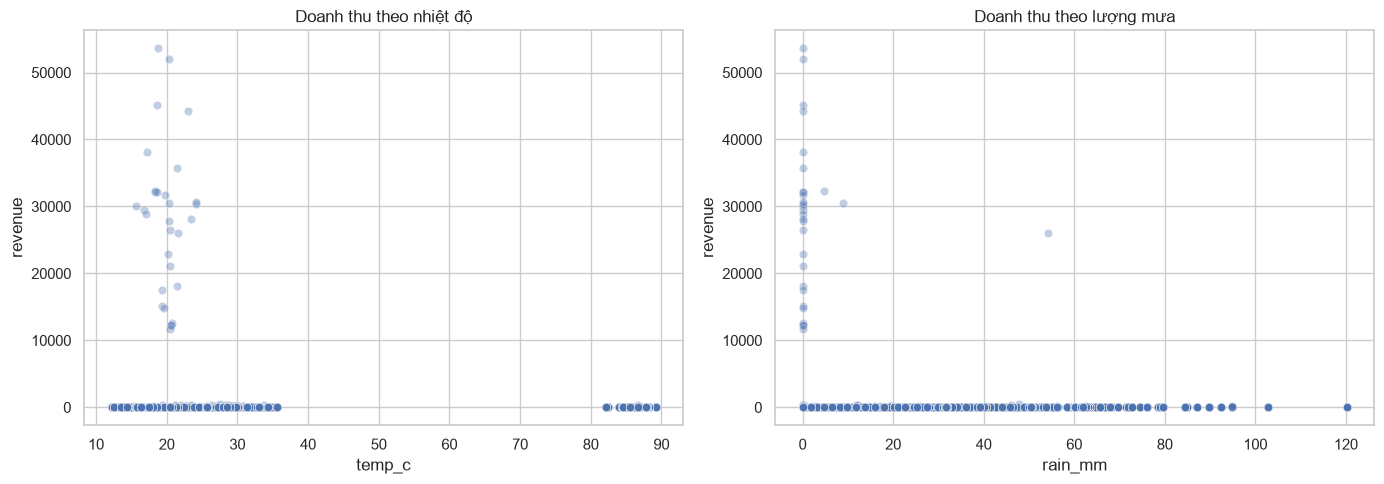

,count,mean,median,std
is_holiday,,,,
0,25307,51.31,18.35,1002.83
1,1325,52.06,15.85,1239.42


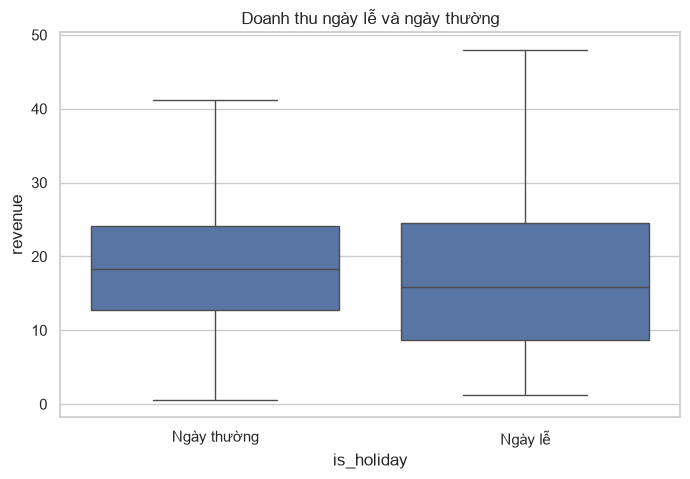

===== CÁC NGÀY TẾT 2026 =====


,date,holiday_name,type
43,2026-02-10,Ong Cong Ong Tao (23 Tet),event
44,2026-02-14,Tet holiday,national_holiday
46,2026-02-15,Tet holiday,national_holiday
47,2026-02-16,Tet holiday,national_holiday
48,2026-02-17,Lunar New Year (Tet),national_holiday
49,2026-02-18,Tet holiday,national_holiday
50,2026-02-19,Tet holiday,national_holiday
51,2026-02-20,Tet holiday,national_holiday
52,2026-02-21,Tet holiday,national_holiday
53,2026-02-22,Tet holiday,national_holiday


,count,mean,median
date,,,


In [21]:
# ===== EDA 3: THỜI TIẾT VÀ NGÀY LỄ =====
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Ghép doanh thu với cửa hàng
eda = train_clean.merge(
    stores_clean,
    on="store_id",
    how="left",
    validate="many_to_one"
)

# Ghép thời tiết theo ngày và thành phố
eda = eda.merge(
    weather_clean,
    on=["date", "city"],
    how="left",
    validate="many_to_one"
)

# Tổng hợp ngày lễ theo ngày để không nhân bản doanh thu
holiday_day = holidays_clean.groupby("date").agg(
    is_holiday=("holiday_name", "size"),
    holiday_names=(
        "holiday_name",
        lambda x: " | ".join(x.dropna().astype(str).unique())
    )
).reset_index()

eda = eda.merge(
    holiday_day,
    on="date",
    how="left",
    validate="many_to_one"
)
eda["is_holiday"] = eda["is_holiday"].fillna(0).gt(0).astype(int)

print("Số dòng sau khi ghép:", len(eda))
print("Số dòng ban đầu:", len(train_clean))
print("Thiếu nhiệt độ:", eda["temp_c"].isna().sum())
print("Thiếu lượng mưa:", eda["rain_mm"].isna().sum())

# 1. Doanh thu theo nhiệt độ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=eda, x="temp_c", y="revenue",
    alpha=0.35, ax=axes[0]
)
axes[0].set_title("Doanh thu theo nhiệt độ")

sns.scatterplot(
    data=eda, x="rain_mm", y="revenue",
    alpha=0.35, ax=axes[1]
)
axes[1].set_title("Doanh thu theo lượng mưa")

plt.tight_layout()
plt.show()

# 2. So sánh ngày lễ và ngày thường
display(
    eda.groupby("is_holiday")["revenue"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=eda, x="is_holiday", y="revenue",
    showfliers=False
)
plt.xticks([0, 1], ["Ngày thường", "Ngày lễ"])
plt.title("Doanh thu ngày lễ và ngày thường")
plt.show()

# 3. Tìm ngày Tết năm 2026 trong holidays.csv
tet_mask = holidays_clean["holiday_name"].str.contains(
    r"Tet|Tết|Lunar New Year",
    case=False, na=False
)

tet_2026 = holidays_clean[
    tet_mask & (holidays_clean["date"].dt.year == 2026)
].sort_values("date")

print("===== CÁC NGÀY TẾT 2026 =====")
display(tet_2026)

if not tet_2026.empty:
    tet_dates = tet_2026["date"].drop_duplicates()
    display(
        eda[eda["date"].isin(tet_dates)]
        .groupby("date")["revenue"]
        .agg(["count", "mean", "median"])
        .round(2)
    )
else:
    print("Không tìm thấy ngày Tết 2026 theo từ khóa trên.")

===== THỐNG KÊ DOANH THU =====


,revenue
count,26632.000000
mean,51.343409
std,1015.877130
min,0.570000
50%,18.280000
90%,30.450000
95%,34.594500
99%,44.806900
99.9%,12434.390000
max,53600.000000


Doanh thu thiếu: 0
Doanh thu <= 0: 0
Doanh thu > 1000: 31


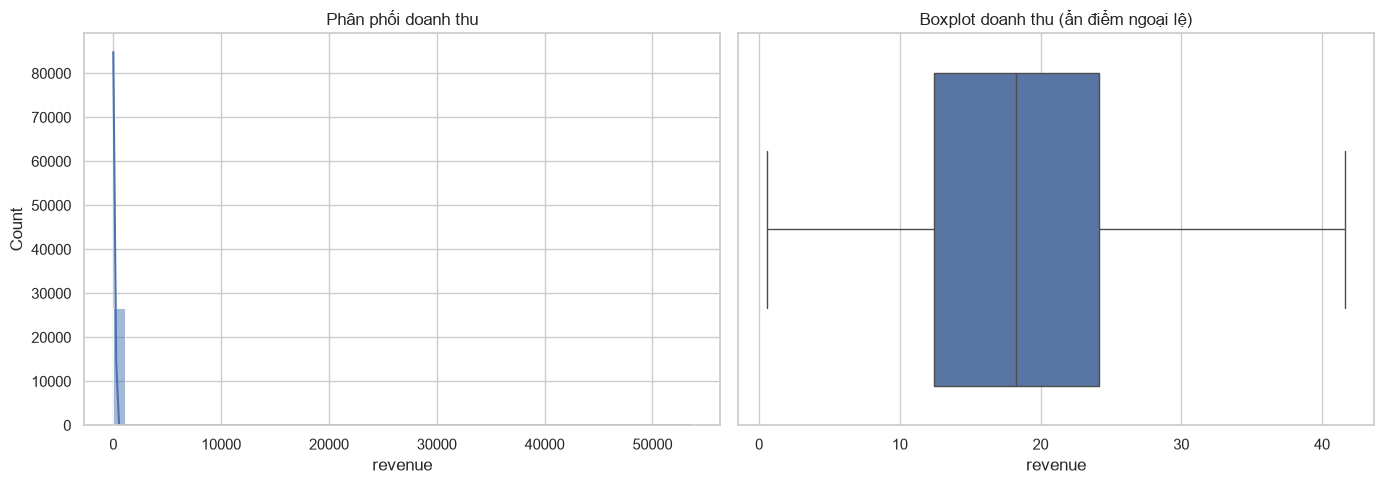

,date,store_id,is_promo,revenue
2139,2024-03-07,S12,1,53600.0
2071,2024-03-05,S12,1,51990.0
2173,2024-03-08,S12,1,45130.0
2880,2024-03-29,S12,1,44280.0
2105,2024-03-06,S12,0,38120.0
2813,2024-03-27,S12,0,35780.0
2373,2024-03-14,S12,0,32380.0
2273,2024-03-11,S12,0,32190.0
2610,2024-03-21,S12,0,32110.0
2579,2024-03-20,S12,0,31670.0


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

print("===== THỐNG KÊ DOANH THU =====")
display(train_clean["revenue"].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
).to_frame("revenue"))

print("Doanh thu thiếu:", train_clean["revenue"].isna().sum())
print("Doanh thu <= 0:", (train_clean["revenue"] <= 0).sum())
print("Doanh thu > 1000:", (train_clean["revenue"] > 1000).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=train_clean,
    x="revenue",
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Phân phối doanh thu")

sns.boxplot(
    data=train_clean,
    x="revenue",
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Boxplot doanh thu (ẩn điểm ngoại lệ)")

plt.tight_layout()
plt.show()

# Đánh dấu để kiểm tra, không xóa outlier ở bước EDA
train_clean["revenue_extreme_flag"] = (
    train_clean["revenue"] > 1000
)

display(
    train_clean.loc[
        train_clean["revenue_extreme_flag"],
        ["date", "store_id", "is_promo", "revenue"]
    ].sort_values("revenue", ascending=False).head(20)
)